<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# OBJECTIF DE CE NOTEBOOK

Analyser le stock et les ventes du site Bottleneck à partir de 3 fichiers (ERP, web, liaison) : nettoyer, fusionner, puis calculer le CA, le stock et la marge.

**Hypothèses (à confirmer avec le client)**
- `total_sales` = ventes du mois d'octobre (extraction au 31 octobre).
- `price` = prix de vente TTC (TVA 20 %) ; `purchase_price` = prix d'achat HT.
- Prix négatifs : erreurs de saisie, exclus des calculs. Stocks négatifs : ramenés à 0.
- Doublons du fichier web : on garde la première ligne par SKU, après contrôle des ventes.

**Pour exécuter** : placer `erp.xlsx`, `web.xlsx` et `liaison.xlsx` dans le même dossier, puis *Kernel > Restart & Run All*.
Librairies : pandas, numpy, matplotlib, seaborn, plotly, openpyxl ; pandera (optionnel, pour le test comparatif des validations).

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
#Importation de la librairie Pandas
import pandas as pd

In [2]:
#Importation de la librairie plotly express
import plotly.express as px

In [3]:
import numpy as np

In [4]:
import matplotlib.pyplot as plt

In [5]:
#Importation de la librairie seaborn
import seaborn as sns

In [6]:
#Afficher toutes les colonnes d'un dataframe
pd.set_option("display.max_columns", None)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [7]:
#Importation du fichier web.xlsx
df_web = pd.read_excel("web.xlsx")
#Importation du fichier erp.xlsx
df_erp = pd.read_excel("erp.xlsx")
#Importation du fichier liaison.xlsx
df_liaison = pd.read_excel("liaison.xlsx")

/usr/local/lib/python3.12/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/usr/local/lib/python3.12/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/usr/local/lib/python3.12/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [8]:
#Afficher les dimensions du dataset
print("Dimensions", df_erp.shape)
print("Nombre de lignes", df_erp.shape[0])
print("Nombre de colonnes", df_erp.shape[1])

Dimensions (825, 6)
Nombre de lignes 825
Nombre de colonnes 6


In [9]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
df_erp.info()

<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    str    
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 38.8 KB


In [10]:
#Afficher les 5 premières lignes de la table
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [11]:
#Vérifier si il y a des lignes en doublon dans la colonne product_id

df_erp["product_id"].duplicated().sum()


np.int64(0)

In [12]:
#Afficher les valeurs distinctes de la colonne stock_status
df_erp['stock_status'].unique()
#À quelle(s) autre(s) colonne(s) sont-elles liées ?
#Stock_quantity 

<StringArray>
['instock', 'outofstock']
Length: 2, dtype: str

In [13]:
#Création d'une colonne "stock_status_2"
#La valeur de cette deuxième colonne sera fonction de la valeur dans la colonne "stock_quantity"
#Si la valeur de la colonne "stock_quantity" est nulle, renseigner "outofstock" sinon mettre "instock"
df_erp["stock_status_2"] = np.where(df_erp["stock_quantity"] <= 0, "outofstock", "instock")
df_erp["stock_status_2"].value_counts()

stock_status_2
instock       733
outofstock     92
Name: count, dtype: int64

In [14]:
#Vérifions que les 2 colonnes sont identiques:
#Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
#La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous:
df_erp["stock_status"] == df_erp["stock_status_2"]
#Le résultat est l'affichage de True ou False pour chacune des lignes du dataset
#C'est un bon début, mais difficile à exploiter

0       True
1       True
2       True
3       True
4      False
       ...  
820     True
821     True
822     True
823     True
824     True
Length: 825, dtype: bool

In [15]:
#Mais il est possible de synthétiser ce résultat en effectuant la somme de cette colonne:
comparaison = df_erp["stock_status"] == df_erp["stock_status_2"]
comparaison.sum()

#True vaut 1 et False 0
#Nous devrions obtenir la somme de 824 qui correspond au nombre de lignes dans ce dataset


np.int64(823)

In [16]:
#Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
##Dans ce cas je vous donne ce lien pour apprendre à réaliser des filtres dans Pandas:
##https://bitbucket.org/hrojas/learn-pandas/src/master/
##Lesson 3
df_erp[df_erp["stock_status"] != df_erp["stock_status_2"]]

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
4,4039,1,46.0,3,outofstock,23.77,instock
398,4885,1,18.7,0,instock,9.66,outofstock


In [17]:
#Corriger la ou les données incohérentes
df_erp["stock_status"] = df_erp["stock_status_2"]
#Vérification en utilisant le même code que plus haut pour afficher les problèmes

df_erp[df_erp["stock_status"] != df_erp["stock_status_2"]]

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [18]:
###############
## LES PRIX  ##
###############

#Vérification des prix: Y a t-il des prix non renseignés, négatifs ou nuls?
print(df_erp["price"].isnull().sum())
#Afficher le ou les prix non renseignés dans la colonne "price"
#Afficher le prix minimum de la colonne "price"
print(df_erp["price"].min())
#Afficher le prix maximum de la colonne "price"
print(df_erp["price"].max())
#Afficher les prix inférieurs à 0 (qu'est-ce qu'il faut en faire ?) les supprimer ou alors les mettre en positifs
df_erp[df_erp["price"] < 0]


0
-20.0
225.0


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
151,4233,0,-20.0,0,outofstock,10.33,outofstock
469,5017,0,-8.0,0,outofstock,4.34,outofstock
739,6594,0,-9.1,19,instock,4.61,instock


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [19]:
#######################
### stock_quantity  ###
#######################

#Vérification de la colonne stock quantity
#Afficher la quantité minimum de la colonne "stock_quantity"
print("minimum", df_erp["stock_quantity"].min())

#Afficher la quantité maximum de la colonne "stock_quantity"
print("maximum", df_erp["stock_quantity"].max())

#Afficher les stocks inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
df_erp[df_erp["stock_quantity"] < 0]


minimum -10
maximum 145


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
449,4973,0,10.0,-10,outofstock,4.96,outofstock
573,5700,1,44.5,-1,outofstock,22.30,outofstock


**Test comparatif : comment détecter les valeurs négatives ?**

- Option A : règles maison avec pandas.
- Option B : schéma de validation Pandera (`pip install pandera`).

Critères : anomalies détectées, lisibilité, durée d'exécution, reproductibilité.

In [20]:
import time

#Option A : règles maison (pandas)
t0 = time.perf_counter()
regles_maison = {"prix négatifs": int((df_erp["price"] < 0).sum()),
                 "stocks négatifs": int((df_erp["stock_quantity"] < 0).sum())}
duree_A = time.perf_counter() - t0
print("Option A - règles maison :", regles_maison, "| durée :", round(duree_A * 1000, 2), "ms")

#Option B : schéma Pandera
try:
    import pandera.pandas as pa
    schema_erp = pa.DataFrameSchema({
        "price": pa.Column(float, pa.Check.ge(0)),
        "stock_quantity": pa.Column(int, pa.Check.ge(0)),
    })
    t0 = time.perf_counter()
    try:
        schema_erp.validate(df_erp, lazy=True)
        print("Option B - Pandera : aucune anomalie")
    except pa.errors.SchemaErrors as erreurs:
        print("Option B - Pandera :", len(erreurs.failure_cases), "anomalies détectées")
        print(erreurs.failure_cases[["column", "check", "failure_case"]])
    duree_B = time.perf_counter() - t0
    print("Option B - durée :", round(duree_B * 1000, 2), "ms")
except ImportError:
    print("Pandera non installé : pip install pandera")

Option A - règles maison : {'prix négatifs': 3, 'stocks négatifs': 2} | durée : 0.96 ms


Option B - Pandera : 5 anomalies détectées
           column                        check  failure_case
0           price  greater_than_or_equal_to(0)         -20.0
1           price  greater_than_or_equal_to(0)          -8.0
2           price  greater_than_or_equal_to(0)          -9.1
3  stock_quantity  greater_than_or_equal_to(0)         -10.0
4  stock_quantity  greater_than_or_equal_to(0)          -1.0
Option B - durée : 21.13 ms


**Décision de nettoyage ERP**

- Prix négatifs (erreurs de saisie) : mis à `NaN`, donc exclus des calculs (CA, marge). À faire corriger par l'équipe métier.
- Stocks négatifs (erreurs de saisie) : ramenés à 0.

In [21]:
nb_prix_neg = (df_erp["price"] < 0).sum()
df_erp.loc[df_erp["price"] < 0, "price"] = np.nan

nb_stock_neg = (df_erp["stock_quantity"] < 0).sum()
df_erp.loc[df_erp["stock_quantity"] < 0, "stock_quantity"] = 0

print("Prix négatifs exclus :", nb_prix_neg)
print("Stocks négatifs ramenés à 0 :", nb_stock_neg)

#Contrôles : plus aucune valeur négative
assert (df_erp["price"].dropna() >= 0).all()
assert (df_erp["stock_quantity"] >= 0).all()

Prix négatifs exclus : 3
Stocks négatifs ramenés à 0 : 2


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [22]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles?
df_erp["onsale_web"].sum()

np.int64(716)

In [23]:
#Quelles sont les colonnes à conserver selon vous? toutes sauf stock_status_2


In [24]:
#Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante 
#avec la colonne "stock_status".
df_erp = df_erp.drop(columns=["stock_status_2"])

In [25]:
df_erp.columns

Index(['product_id', 'onsale_web', 'price', 'stock_quantity', 'stock_status',
       'purchase_price'],
      dtype='str')

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [26]:
######################
##   prix d'achat   ##
######################

#Vérification de la colonne purchase_price : 
#Afficher le ou les prix non renseignés dans la colonne "purchase_price"
print("non rensigné", df_erp["purchase_price"].isnull().sum())
#Afficher le prix minimum de la colonne "purchase_price"
print("minimum", df_erp["purchase_price"].min())
#Afficher le prix maximum de la colonne "purchase_price"
print("maximum", df_erp["purchase_price"].max())

non rensigné 0
minimum 2.74
maximum 137.81


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [27]:
#Dimension du dataset
print("Dimension", df_web.shape)
#Nombre d'observations
print("nombre de lignes", df_web.shape[0])
#Nombre de caractéristiques
print("nombre de colonnes", df_web.shape[1])


Dimension (1513, 29)
nombre de lignes 1513
nombre de colonnes 29


In [28]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
df_web.info()

<class 'pandas.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    str           
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[us]
 10  post_date_gmt          1430 non-null   datetime64[us]
 11  post_content           0 non-null      float64       
 12  product_type           1429 non-null   str           
 13  post_title    

In [29]:
#Selon vous, quelles sont les colonnes à conserver ?
#sku - identifiant produit pour la fusion
#total_sales - nombre de ventes → indispensable pour le CA
#average_rating - note client → utile pour la qualité perçue
#product_type - type de produit (Vin, Champagne...)
#post_title -  nom du produit → pour identifier les produits dans les graphiques

In [30]:
#Si vous avez défini des colonnes à supprimer, effectuer l'opération
df_web = df_web[["sku", "total_sales", "average_rating", "product_type", "post_title"]]

In [31]:
print("dimension dataframe", df_web.shape)
df_web.info()

dimension dataframe (1513, 5)
<class 'pandas.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sku             1428 non-null   object 
 1   total_sales     1430 non-null   float64
 2   average_rating  1430 non-null   float64
 3   product_type    1429 non-null   str    
 4   post_title      1430 non-null   str    
dtypes: float64(2), object(1), str(2)
memory usage: 59.2+ KB


In [32]:
#Visualisation des valeurs de la colonne sku
df_web["sku"].unique()
#Quelles sont les valeurs qui ne semblent pas respecter la régle de codification?
#'13127-1' → un nombre avec un tiret
#'bon-cadeau-25-euros' → du texte
#nan → valeur manquante

array([11862, 16057, 14692, 16295, 15328, 15471, 16515, 16246, nan, 13572,
       16513, 16585, 16269, 15526, 12869, 15575, 11586, 14338, 15425,
       16560, 15361, 13809, 11587, 15022, 14323, 16342, 16029, 15475,
       13754, 14680, 15875, 9636, 13849, 13662, 16564, 13557, 15429,
       14712, 15032, 15481, 15448, 16580, 15441, 804, 15300, 13958, 16071,
       15678, 13895, 15711, 12882, 16053, 13766, 16247, 12640, 15292,
       15476, 15670, 16189, 16038, 14864, 16044, 15324, 15531, 15953,
       15413, 15733, 14366, 15895, 15892, 16472, 15185, 16010, 15793,
       15849, 12315, 15741, 15934, 15148, 15781, 15659, 15106, 15490,
       14507, 14149, 16307, 13736, 14090, 16037, 15758, 14661, 12587,
       15337, 15489, 15201, 16305, 16131, 13435, 15747, 12203, 14509,
       14768, 16262, 14561, 16505, 15717, 16129, 13460, 15871, 15940,
       11602, 13127, 13520, 15480, 13032, 15436, 15269, 15910, 19821,
       16263, 15138, 15146, 15126, 15482, 16186, 13905, 16540, 15856,
       1567

In [33]:
#Si vous avez identifié des codes articles ne respectant pas la régle de codification, consultez-les
print("bon cadeau", df_web[df_web["sku"] == 'bon-cadeau-25-euros'])
print("numéro avec tiret", df_web[df_web["sku"] == '13127-1'])

bon cadeau                       sku  total_sales  average_rating product_type  \
842   bon-cadeau-25-euros          7.0             0.0        Autre   
1387  bon-cadeau-25-euros          7.0             0.0          NaN   

             post_title  
842   Bon cadeau de 25€  
1387  Bon cadeau de 25€  
numéro avec tiret           sku  total_sales  average_rating product_type  \
272   13127-1          4.0             0.0          Vin   
1117  13127-1          4.0             0.0          Vin   

                                        post_title  
272   Clos du Mont-Olivet Châteauneuf-du-Pape 2007  
1117  Clos du Mont-Olivet Châteauneuf-du-Pape 2007  


In [34]:
#Identifier les lignes sans code article
df_web[df_web["sku"].isnull()]

,sku,total_sales,average_rating,product_type,post_title
8,NaN,NaN,NaN,NaN,NaN
20,NaN,NaN,NaN,NaN,NaN
30,NaN,NaN,NaN,NaN,NaN
37,NaN,NaN,NaN,NaN,NaN
41,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...
1384,NaN,NaN,NaN,NaN,NaN
1429,NaN,NaN,NaN,NaN,NaN
1432,NaN,NaN,NaN,NaN,NaN
1445,NaN,NaN,NaN,NaN,NaN


In [35]:
#Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre
#bon cadeau on vire parce ca correspond pas l'autre on garde car c'est un vrai produit et 
#nan on vire parce que on sait pas ça correspond à quoi
# Supprimer le bon cadeau
df_web = df_web[df_web["sku"] != 'bon-cadeau-25-euros']
df_web.shape

(1511, 5)

In [36]:
#La clé pour chaque ligne est-elle unique? autrement dit, y a-t-il des doublons?
df_web["sku"].duplicated().sum()

np.int64(797)

In [37]:
#Les lignes sans code article semblent être toutes non renseignées
#Pour s'en assurer, réaliser les étapes suivantes:
#1 - Créer un dataframe avec uniquement les lignes sans code article
df_web_null = df_web[df_web["sku"].isnull()]
#2 - Utiliser la fonction df.info() sur ce nouveau dataframe pour observer le nombre de valeurs renseignées dans chacune des colonnes
df_web_null.info()
#3 - Que constatez-vous?
#la pluplart ont des valeurs manquantes autre que le sku


<class 'pandas.DataFrame'>
Index: 85 entries, 8 to 1457
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sku             0 non-null      object 
 1   total_sales     2 non-null      float64
 2   average_rating  2 non-null      float64
 3   product_type    2 non-null      str    
 4   post_title      2 non-null      str    
dtypes: float64(2), object(1), str(2)
memory usage: 4.0+ KB


In [38]:
# Supprimer les NaN
df_web = df_web[df_web["sku"].notna()]

In [39]:
df_web.shape

(1426, 5)

In [40]:
#Contrôle avant dédoublonnage : les lignes en double ont-elles les mêmes ventes ?
doublons = df_web[df_web["sku"].duplicated(keep=False)]
ventes_distinctes = doublons.groupby("sku")["total_sales"].nunique()
print("SKU présents en double :", doublons["sku"].nunique())
print("SKU dont les ventes diffèrent entre les doublons :", (ventes_distinctes > 1).sum())
#Si ce nombre est supérieur à 0, garder la première ligne est un choix à justifier.

SKU présents en double : 713
SKU dont les ventes diffèrent entre les doublons : 4


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [41]:
#Dimension du dataset
print("dimension", df_liaison.shape)
#Nombre d'observations
print("Nombre de lignes", df_liaison.shape[0])
#Nombre de caractéristiques
print("Nombre de colonnes", df_liaison.shape[1])


dimension (825, 2)
Nombre de lignes 825
Nombre de colonnes 2


In [42]:
#Consulter le nombre de colonnes
df_liaison.info()
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
#825 produits dans l'ERP, mais seulement 734 ont un équivalent sur le site web.

<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


In [43]:
#Les valeurs de la colonne "product_id" sont-elles toutes uniques?
df_liaison["product_id"].duplicated().sum()

np.int64(0)

In [44]:
#Les valeurs de la colonne "id_web" sont-elles toutes uniques?
df_liaison["id_web"].duplicated().sum()
#sur les 734 non null il y a 90 doublons

np.int64(90)

In [45]:
#Avons-nous des articles sans correspondance?
df_liaison.isnull().sum()

id_web        91
product_id     0
dtype: int64

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [46]:
#Fusion des fichiers df_erp et df_liaison
#on veut garder tous les produits de l'ERP, même ceux sans correspondance web
df_merge = pd.merge(df_erp, df_liaison, on="product_id", how="left") 

assert len(df_merge) == len(df_erp)  #la fusion ne doit ni ajouter ni perdre de lignes ERP


In [47]:
df_merge.shape

(825, 7)

In [48]:
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,instock,23.77


In [49]:
df_merge.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web
0,3847,1,24.2,16,instock,12.88,15298
1,3849,1,34.3,10,instock,17.54,15296
2,3850,1,20.8,0,outofstock,10.64,15300
3,4032,1,14.1,26,instock,6.92,19814
4,4039,1,46.0,3,instock,23.77,19815


In [50]:
#Y a t-il des lignes ne "matchant" pas entre les 2 fichiers?
df_merge.isnull().sum()

product_id         0
onsale_web         0
price              3
stock_quantity     0
stock_status       0
purchase_price     0
id_web            91
dtype: int64

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [51]:
#supprimer les doublons de df_web car un produit peut être plusieurs fois dans le df_web 
df_web = df_web.drop_duplicates(subset=["sku"])
#Fusionner les datasets df_merge et df_web
df_merge = pd.merge(df_merge, df_web, left_on="id_web", right_on="sku", how="left")
assert len(df_merge) == len(df_erp)  #idem après la fusion avec le web


In [52]:
df_merge.shape

(825, 12)

In [53]:
#Avons-nous des lignes sans correspondance?
df_merge.isnull().sum()

product_id          0
onsale_web          0
price               3
stock_quantity      0
stock_status        0
purchase_price      0
id_web             91
sku               112
total_sales       112
average_rating    112
product_type      112
post_title        112
dtype: int64

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

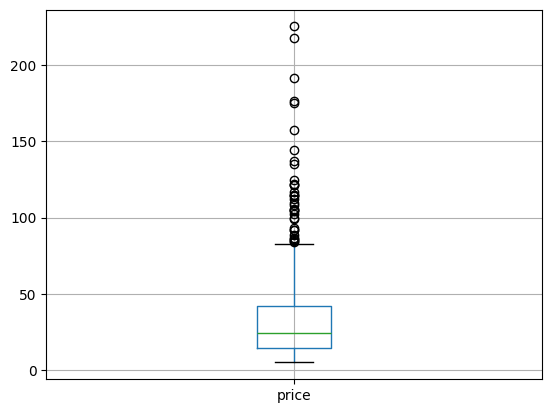

In [54]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas
df_merge.boxplot(column=["price"])
plt.show()

In [55]:
#Autre méthode avec plotly express (les prix négatifs ont été exclus à l'étape 2.1.1.2)
px.box(df_merge, y="price")

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [56]:
#C'est quoi le Z-score ?
#C'est un nombre qui dit à combien de "distances standard" une valeur est éloignée de la moyenne.
#En clair : est-ce que ce prix est normal ou vraiment bizarre ?

#Z-score proche de 0 → valeur normale ✅
#Z-score > 3 ou < -3 → valeur aberrante ⚠️

In [57]:
#Calculer la moyenne et l'écart-type du prix (l'écart-type mesure la dispersion autour de la moyenne)
moyenne_prix = df_merge["price"].mean()
ecart_type_prix = df_merge["price"].std()
print("moyenne", round(moyenne_prix, 2))
print("ecart type", round(ecart_type_prix, 2))

#Calculer le Z-score
df_merge["zscore"] = (df_merge["price"] - moyenne_prix) / ecart_type_prix

moyenne 32.35
ecart type 26.62


In [58]:
#Quel est le seuil prix dont le z-score est supérieur à 3?
df_merge.query("zscore > 3 or zscore < -3")

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,sku,total_sales,average_rating,product_type,post_title,zscore
208,4352,1,225.0,0,outofstock,137.81,15940,15940,11.0,0.0,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,7.236362
227,4402,1,176.0,11,instock,78.25,3510,3510,3.0,0.0,Cognac,Cognac Frapin VIP XO,5.395810
230,4406,1,157.0,12,instock,69.08,7819,7819,4.0,0.0,Cognac,Cognac Frapin Château de Fontpinot 1989 20 Ans...,4.682127
242,4594,1,144.0,0,outofstock,87.36,NaN,NaN,NaN,NaN,NaN,NaN,4.193817
411,4904,1,137.0,9,instock,67.95,14220,14220,3.0,0.0,Vin,Domaine Des Croix Corton Charlemagne Grand Cru...,3.930881
460,5001,1,217.5,18,instock,116.87,14581,14581,2.0,0.0,Vin,David Duband Charmes-Chambertin Grand Cru 2014,6.954644
556,5612,1,124.8,19,instock,66.41,14915,14915,1.0,0.0,Vin,Domaine Weinbach Gewurztraminer Grand Cru Furs...,3.472621
598,5767,1,175.0,12,instock,90.42,15185,15185,4.0,0.0,Vin,Camille Giroud Clos de Vougeot 2016,5.358248
635,5892,1,191.3,98,instock,116.06,14983,14983,6.0,0.0,Champagne,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,5.970513
651,5917,1,122.0,12,instock,54.24,14775,14775,3.0,0.0,Whisky,Wemyss Malts Single Cask Scotch Whisky Choc 'n...,3.367447


In [59]:
df_merge["zscore"].head()

0   -0.306144
1    0.073235
2   -0.433856
3   -0.685523
4    0.512714
Name: zscore, dtype: float64

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [60]:
#Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion
df_merge.describe()

,product_id,onsale_web,price,stock_quantity,purchase_price,total_sales,average_rating,zscore
count,825.000000,825.000000,822.000000,825.000000,825.000000,713.000000,713.0,8.220000e+02
mean,5162.597576,0.867879,32.350304,21.602424,16.940582,8.518934,0.0,-1.123729e-16
std,902.644635,0.338828,26.622453,21.917863,14.561840,8.157164,0.0,1.000000e+00
min,3847.000000,0.000000,5.200000,0.000000,2.740000,0.000000,0.0,-1.019827e+00
25%,4348.000000,1.000000,14.600000,7.000000,7.590000,5.000000,0.0,-6.667419e-01
50%,4907.000000,1.000000,24.400000,18.000000,12.710000,8.000000,0.0,-2.986315e-01
75%,5805.000000,1.000000,42.000000,30.000000,22.020000,11.000000,0.0,3.624646e-01
max,7338.000000,1.000000,225.000000,145.000000,137.810000,122.000000,0.0,7.236362e+00


In [61]:
#Seuils des valeurs aberrantes par la méthode de l'intervalle interquartile (IQR)
Q1 = df_merge["price"].quantile(0.25)
Q3 = df_merge["price"].quantile(0.75)
print(Q1, Q3)

#IQR = largeur de la boîte du boxplot
IQR = Q3 - Q1
print(IQR)

#Un prix est considéré comme anormal s'il est hors de [Q1 - 1.5 x IQR ; Q3 + 1.5 x IQR]
seuil_bas = Q1 - 1.5 * IQR
seuil_haut = Q3 + 1.5 * IQR
print(seuil_bas, seuil_haut)

14.6 42.0
27.4
-26.499999999999993 83.1


In [62]:
df_merge.query("price > @seuil_haut or price < @seuil_bas")

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,sku,total_sales,average_rating,product_type,post_title,zscore
19,4055,0,86.1,0,outofstock,37.88,NaN,NaN,NaN,NaN,NaN,NaN,2.018961
66,4115,1,100.0,12,instock,52.70,15382,15382,1.0,0.0,Vin,Zind-Humbrecht Riesling Grand Cru Rangen De Th...,2.541077
68,4132,1,88.4,7,instock,44.30,11668,11668,5.0,0.0,Vin,Zind-Humbrecht Pinot Gris Grand Cru Rangen De ...,2.105354
208,4352,1,225.0,0,outofstock,137.81,15940,15940,11.0,0.0,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,7.236362
214,4359,1,85.6,112,instock,51.93,13853,13853,7.0,0.0,Champagne,Champagne Larmandier-Bernier Grand Cru Les Che...,2.000180
227,4402,1,176.0,11,instock,78.25,3510,3510,3.0,0.0,Cognac,Cognac Frapin VIP XO,5.395810
228,4404,1,108.5,17,instock,52.22,3507,3507,4.0,0.0,Cognac,Cognac Frapin Château de Fontpinot XO,2.860356
230,4406,1,157.0,12,instock,69.08,7819,7819,4.0,0.0,Cognac,Cognac Frapin Château de Fontpinot 1989 20 Ans...,4.682127
231,4407,1,104.0,14,instock,46.71,3509,3509,5.0,0.0,Cognac,Cognac Frapin Cigar Blend,2.691326
240,4582,1,109.6,18,instock,53.80,12857,12857,1.0,0.0,Vin,Château de Meursault Puligny-Montrachet 1er Cr...,2.901675


In [63]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
df_merge.query("price > @seuil_haut or price < @seuil_bas").shape[0]

36

In [64]:
round((df_merge.query("price > @seuil_haut or price < @seuil_bas").shape[0] / df_merge.shape[0] ) * 100, 2)

4.36

In [65]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?
df_merge.query("price > @seuil_haut or price < @seuil_bas")["product_type"].value_counts()
#À vérifier produit par produit : ces catégories contiennent des produits premium (grands crus, champagnes, cognacs, whiskies) dont un prix élevé est plausible.
#Les prix négatifs (vraies erreurs) ont déjà été exclus à l'étape 2.1.1.2.

product_type
Vin          19
Champagne     6
Cognac        4
Whisky        3
Name: count, dtype: int64

In [66]:
#Comparaison des deux méthodes
n_z = df_merge.query("zscore > 3 or zscore < -3").shape[0]
n_iqr = df_merge.query("price > @seuil_haut or price < @seuil_bas").shape[0]
print("Valeurs aberrantes - Z-score :", n_z, "| IQR :", n_iqr)

#Z-score : distance à la moyenne en écarts-types ; sensible aux valeurs extrêmes car la moyenne l'est.
#IQR : basé sur les quartiles ; plus robuste. Les deux comptes diffèrent car les formules diffèrent.

Valeurs aberrantes - Z-score : 17 | IQR : 36


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [67]:
#Hypothèses : total_sales = ventes d'octobre ; price = prix TTC. Le CA est donc un CA TTC du mois.
df_merge["CA"] = df_merge["price"] * df_merge["total_sales"]
print("CA du site web (octobre, TTC) :", round(df_merge["CA"].sum(), 2))

CA du site web (octobre, TTC) : 153573.1


In [68]:
df_merge = df_merge.rename(columns={"post_title": "nom_produit"})
df_merge = df_merge.rename(columns={"total_sales": "total_ventes"})

In [69]:
###############################
# Palmarès des articles en CA #
###############################

#Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge
df_merge = df_merge.sort_values("CA", ascending=False)
df_merge.head(3)
#Réinitialiser l'index du dataset par un reset_index
df_merge = df_merge.sort_values("CA", ascending=False).reset_index(drop=True)


#Afficher les 20 premiers articles en CA
df_merge.head(20)
#Graphique en barre des 20 premiers articles avec plotly express - changer le nom de la colonne 
px.bar(df_merge.head(20), y="CA", x="nom_produit")

In [70]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part du CA de la ligne dans le dataset
df_merge["part_CA"] = (df_merge["CA"] / df_merge["CA"].sum()) * 100
df_merge["part_CA"]

#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_merge["part_CA_cumulee"] = df_merge["part_CA"].cumsum()
df_merge.head()

#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% du CA
print(df_merge.query("part_CA_cumulee < 80").shape[0])

#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
round((df_merge.query("part_CA_cumulee < 80").shape[0] / df_merge.shape[0]) * 100, 2)

420


50.91

In [71]:
#Lecture : comparer la proportion de produits obtenue ci-dessus à 20 %.
#Si elle est nettement supérieure, la règle 20/80 n'est pas respectée.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

In [72]:
#####################################
# Palmarès des articles en quantité #
#####################################

#Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge
df_merge = df_merge.sort_values(by="total_ventes", ascending=False)

#Réinitialiser l'index du dataset par un reset_index
df_merge = df_merge.sort_values(by="total_ventes", ascending=False).reset_index(drop=True)

#Afficher les 20 premiers articles en quantité
df_merge.head(20)

#Graphique en barre des 20 premiers articles avec plotly express - changer les noms des colonnes 
px.bar(df_merge.head(20), y="total_ventes", x="nom_produit")



In [73]:
##################################
# Calculer le 20 / 80 en quantité #
##################################

#Part en quantité de chaque ligne, puis somme cumulative (le dataset est trié par quantité décroissante)
df_merge["part_quantite"] = (df_merge["total_ventes"] / df_merge["total_ventes"].sum()) * 100
df_merge["part_quantite_cumulee"] = df_merge["part_quantite"].cumsum()

#Nombre d'articles représentant 80% des ventes en quantité, et part du catalogue
n80_q = df_merge.query("part_quantite_cumulee < 80").shape[0]
print(n80_q)
print(round((n80_q / df_merge.shape[0]) * 100, 2))

423
51.27


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

In [74]:
###################################
# Calculer le nombre de mois de stock #
###################################

#Mois de stock = stock / ventes du mois (total_ventes = ventes d'octobre).
#Si un produit n'a aucune vente (ou pas de correspondance web), la rotation n'est pas calculable : NaN.
#Ces produits sont suivis à part avec l'indicateur "stock_dormant" (stock > 0 et aucune vente).
ventes_positives = df_merge["total_ventes"].where(df_merge["total_ventes"] > 0)
df_merge["rotation_stock"] = df_merge["stock_quantity"] / ventes_positives
df_merge["stock_dormant"] = (df_merge["stock_quantity"] > 0) & (df_merge["total_ventes"].fillna(0) == 0)

#Tri décroissant du nombre de mois de stock
df_merge = df_merge.sort_values("rotation_stock", ascending=False).reset_index(drop=True)

#Graphique en barre du top 20 des produits qui ont le plus de mois de stock
px.bar(df_merge.head(20), y="rotation_stock", x="nom_produit")
print("Rotation maximale (mois de stock) :", round(df_merge["rotation_stock"].max(), 1))
print("Produits avec plus de 24 mois de stock :", int((df_merge["rotation_stock"] > 24).sum()))

Rotation maximale (mois de stock) : 31.2
Produits avec plus de 24 mois de stock : 4


In [75]:
####################################
# Valorisation des stocks en euros # - combien d'argent est immobilisé dans le stock (au prix d'achat) ?
####################################

df_merge["valorisation_stock_euros"] = df_merge["stock_quantity"] * df_merge["purchase_price"]
print("Valorisation du stock :", round(df_merge["valorisation_stock_euros"].sum(), 2), "€")

Valorisation du stock : 298627.66 €


In [76]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

print("Nombre de bouteilles en stock :", df_merge["stock_quantity"].sum())

Nombre de bouteilles en stock : 17822


In [77]:
#Bilan business (calculé, pas saisi à la main)
stock_total = df_merge["stock_quantity"].sum()
valeur_stock = df_merge["valorisation_stock_euros"].sum()
ca_mois = df_merge["CA"].sum()
n_dormants = df_merge["stock_dormant"].sum()
valeur_dormants = df_merge.loc[df_merge["stock_dormant"], "valorisation_stock_euros"].sum()

print("Bouteilles en stock :", stock_total)
print("Valeur du stock (prix d'achat) :", round(valeur_stock, 2), "€")
print("CA du mois (TTC) :", round(ca_mois, 2), "€")
print("Valeur du stock / CA du mois :", round(valeur_stock / ca_mois, 2))
print("Produits en stock sans vente web en octobre :", n_dormants, "pour", round(valeur_dormants, 2), "€")
print("dont produits non référencés sur le site (pas de correspondance web) :", int((df_merge["stock_dormant"] & df_merge["total_ventes"].isna()).sum()))

#Limites : stock valorisé au prix d'achat HT, CA calculé sur un prix TTC ; un seul mois de ventes ;
#les produits non référencés sur le site (sans correspondance web) comptent comme "sans vente".

Bouteilles en stock : 17822
Valeur du stock (prix d'achat) : 298627.66 €
CA du mois (TTC) : 153573.1 €
Valeur du stock / CA du mois : 1.94
Produits en stock sans vente web en octobre : 68 pour 36564.89 €
dont produits non référencés sur le site (pas de correspondance web) : 65


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [78]:
############################
# Analyse du taux de marge #
############################

#Création de la colonne Prix HT
df_merge["prix_ht"] = df_merge["price"] / 1.2

#Création de la colonne Taux de marge
df_merge["taux_marge"] = (df_merge["prix_ht"] - df_merge["purchase_price"]) / df_merge["prix_ht"] * 100

#Afficher le prix minimum de la colonne "taux_marge"
print(df_merge["taux_marge"].min())

#Afficher le prix maximum de la colonne "taux_marge"
print(df_merge["taux_marge"].max())

-634.98814229249
47.7568


In [79]:
#Affichage de la ligne avec un taux de marge inférieur à 0
df_merge.query("taux_marge < 0")

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,sku,total_ventes,average_rating,product_type,nom_produit,zscore,CA,part_CA,part_CA_cumulee,part_quantite,part_quantite_cumulee,rotation_stock,stock_dormant,valorisation_stock_euros,prix_ht,taux_marge
694,4355,1,12.65,97,instock,77.48,12589,12589,0.0,0.0,Champagne,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,-0.739988,0.0,0.0,100.0,0.0,100.0,NaN,True,7515.56,10.541667,-634.988142
740,4864,0,8.30,0,outofstock,9.99,15154,NaN,NaN,NaN,NaN,NaN,-0.903384,NaN,NaN,NaN,NaN,NaN,NaN,False,0.00,6.916667,-44.433735
769,6324,0,92.00,18,instock,99.00,NaN,NaN,NaN,NaN,NaN,NaN,2.240578,NaN,NaN,NaN,NaN,NaN,NaN,True,1782.00,76.666667,-29.130435
819,7196,0,31.00,55,instock,31.20,NaN,NaN,NaN,NaN,NaN,NaN,-0.050721,NaN,NaN,NaN,NaN,NaN,NaN,True,1716.00,25.833333,-20.774194


In [80]:
#Produits vendus à perte (prix de vente HT inférieur au prix d'achat)
df_merge.query("taux_marge < 0")[["nom_produit", "price", "purchase_price", "taux_marge"]]

,nom_produit,price,purchase_price,taux_marge
694,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,12.65,77.48,-634.988142
740,NaN,8.30,9.99,-44.433735
769,NaN,92.00,99.00,-29.130435
819,NaN,31.00,31.20,-20.774194


In [81]:
df_merge.query("taux_marge < 0")[["nom_produit", "price", "purchase_price", "taux_marge", "total_ventes"]]

,nom_produit,price,purchase_price,taux_marge,total_ventes
694,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,12.65,77.48,-634.988142,0.0
740,NaN,8.30,9.99,-44.433735,NaN
769,NaN,92.00,99.00,-29.130435,NaN
819,NaN,31.00,31.20,-20.774194,NaN


In [82]:
#Taux de marge moyen par type de produit : on exclut ici les produits à marge négative ou nulle
df_merge_positif = df_merge.query("taux_marge > 0")
print(round(df_merge_positif["taux_marge"].min(), 2))
print(round(df_merge_positif["taux_marge"].max(), 2))

22.78
47.76


In [83]:
#Création d'un dataframe avec le taux de marge moyen par type de produit
df_marge_par_type = df_merge_positif.groupby("product_type")["taux_marge"].mean().reset_index()
df_marge_par_type 
#Affichage dans un graphique du taux de marge par type de produit - changer les noms de colonnes 
px.bar(df_marge_par_type, y="taux_marge", x="product_type")
print(df_marge_par_type.round(1))


    product_type  taux_marge
0      Champagne        28.5
1         Cognac        45.1
2            Gin        42.8
3  Huile d'olive        25.0
4            Vin        38.0
5         Whisky        44.9


In [84]:
#Marge en euros pondérée par les ventes : (prix HT - prix d'achat) x ventes du mois
df_merge["ca_ht"] = df_merge["prix_ht"] * df_merge["total_ventes"]
df_merge["marge_euros"] = (df_merge["prix_ht"] - df_merge["purchase_price"]) * df_merge["total_ventes"]

synthese_marge = df_merge.groupby("product_type").agg(ca_ht=("ca_ht", "sum"), marge_euros=("marge_euros", "sum"))
synthese_marge["taux_marge_pondere_%"] = (synthese_marge["marge_euros"] / synthese_marge["ca_ht"] * 100).round(1)
synthese_marge["part_ca_ht_%"] = (synthese_marge["ca_ht"] / synthese_marge["ca_ht"].sum() * 100).round(1)
synthese_marge["part_marge_%"] = (synthese_marge["marge_euros"] / synthese_marge["marge_euros"].sum() * 100).round(1)
synthese_marge = synthese_marge.sort_values("marge_euros", ascending=False).reset_index()
print(synthese_marge)

px.bar(synthese_marge, x="product_type", y="marge_euros")

    product_type          ca_ht   marge_euros  taux_marge_pondere_%  \
0            Vin  105913.333333  40149.093333                  37.9   
1      Champagne   16182.166667   4532.866667                  28.0   
2         Cognac    2641.833333   1188.863333                  45.0   
3         Whisky    2405.500000   1073.040000                  44.6   
4            Gin     420.000000    179.760000                  42.8   
5  Huile d'olive     414.750000    105.790000                  25.5   

   part_ca_ht_%  part_marge_%  
0          82.8          85.0  
1          12.6           9.6  
2           2.1           2.5  
3           1.9           2.3  
4           0.3           0.4  
5           0.3           0.2  


In [85]:
df_merge[["nom_produit", "CA", "total_ventes", "taux_marge", "product_type"]].dropna(subset=["nom_produit"]).sort_values("taux_marge", ascending=False).head(10)

,nom_produit,CA,total_ventes,taux_marge,product_type
534,Cognac Frapin VSOP,187.5,3.0,47.756800,Cognac
642,Wemyss Malts Single Cask Scotch Whisky Chocola...,93.0,1.0,47.754839,Whisky
186,Cognac Frapin Château de Fontpinot 1989 20 Ans...,628.0,4.0,47.200000,Cognac
454,Kingsbarns Distillery Lowland Single Malt Whisky,114.0,2.0,47.200000,Whisky
34,Wemyss Malts Single Cask Scotch Whisky Choc 'n...,366.0,3.0,46.649180,Whisky
35,Cognac Frapin VIP XO,528.0,3.0,46.647727,Cognac
585,Wemyss Malts Blended Malt Scotch Whisky Peat C...,247.5,5.0,46.642424,Whisky
647,Wemyss Malts Blended Malt Scotch Whisky Spice ...,148.5,3.0,46.642424,Whisky
246,Cognac Frapin Cigar Blend,520.0,5.0,46.103846,Cognac
701,Cognac Normandin Mercier VFC,0.0,0.0,45.549249,Cognac


In [86]:
#Comparer le taux de marge moyen simple (graphique précédent) et la marge en euros pondérée par les ventes (cellule ci-dessus)
#avant de conclure sur les catégories à développer : le meilleur taux n'est pas forcément ce qui rapporte le plus en euros.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

In [87]:
#C'est quoi une corrélation ?
#C'est une mesure qui dit si deux variables évoluent ensemble :

#+1 → quand l'une augmente, l'autre augmente aussi
#-1 → quand l'une augmente, l'autre diminue
#0 → pas de lien entre les deux
#Elle répond à la question : "est-ce que deux variables sont liées ?"
#Par exemple :

#Est-ce que les vins chers se vendent moins ?
#Est-ce que les produits avec beaucoup de stock se vendent plus ?

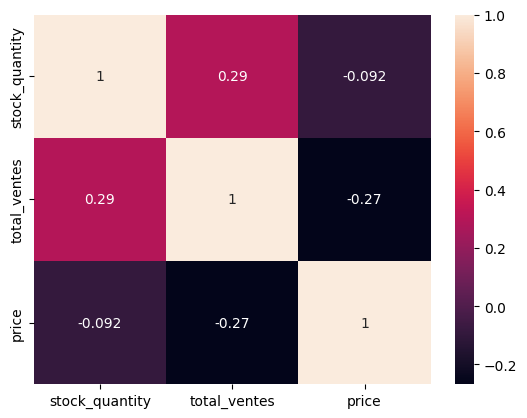

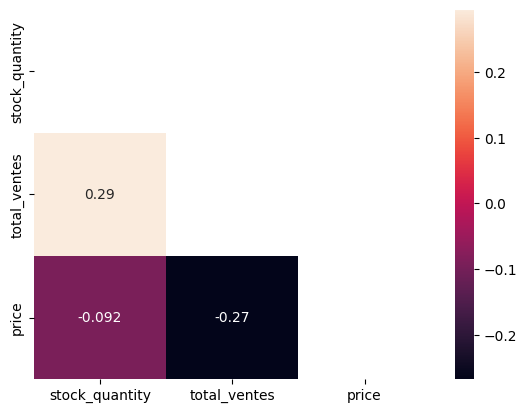

In [88]:
############################
# Analyse des corrélations #
############################

#Importation de Seaborn

#Création d'une heatmap de corrélation avec les variables stock, sales et price
sns.heatmap(df_merge[["stock_quantity", "total_ventes", "price"]].corr(), annot=True)
plt.show()
#On peut également créer un mask pour n'afficher qu'une demi heatmap
mask = np.triu(np.ones_like(df_merge[["stock_quantity", "total_ventes", "price"]].corr()))
sns.heatmap(df_merge[["stock_quantity", "total_ventes", "price"]].corr(), annot=True, mask=mask)
plt.show()

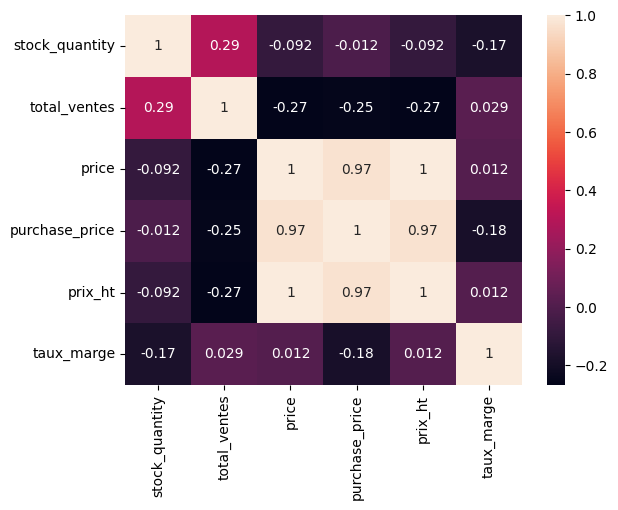

In [89]:
sns.heatmap(df_merge[["stock_quantity", "total_ventes", "price", "purchase_price", "prix_ht", "taux_marge"]].corr(), annot=True)
plt.show()

Pearson :
                stock_quantity  total_ventes  price
stock_quantity            1.00          0.29  -0.09
total_ventes              0.29          1.00  -0.27
price                    -0.09         -0.27   1.00
Spearman :
                stock_quantity  total_ventes  price
stock_quantity            1.00          0.76  -0.47
total_ventes              0.76          1.00  -0.69
price                    -0.47         -0.69   1.00


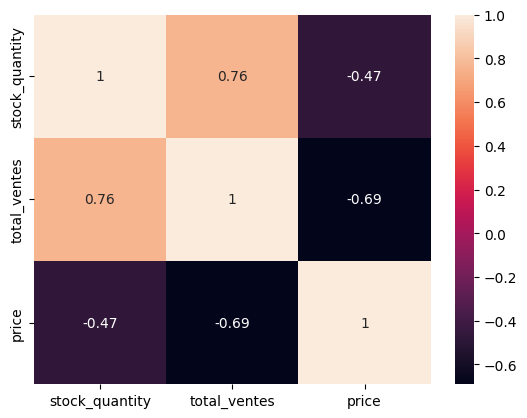

In [90]:
#Comparaison Pearson / Spearman : Spearman est mieux adapté aux distributions asymétriques et aux valeurs extrêmes
cols_corr = ["stock_quantity", "total_ventes", "price"]
print("Pearson :")
print(df_merge[cols_corr].corr().round(2))
print("Spearman :")
print(df_merge[cols_corr].corr(method="spearman").round(2))
sns.heatmap(df_merge[cols_corr].corr(method="spearman"), annot=True)
plt.show()

In [91]:
#Lecture à faire sur les heatmaps Pearson et Spearman (valeurs à lire après exécution).
#Une corrélation ne prouve pas une causalité : un stock élevé peut résulter de ventes élevées (réassort) plutôt que les provoquer.

In [92]:
#Exporter le dataset df_merge dans un fichier Excel pour le partager
df_merge.to_excel("bottleneck_analyse.xlsx", index=False)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>